In [1]:
!pip install -q ultralytics fastapi uvicorn nest-asyncio \
    python-multipart onnx onnxruntime tritonclient[http] \
    pandas matplotlib seaborn requests

In [2]:
import os
import time
import json
import shutil
import threading
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import cv2
import onnx

from PIL import Image
from io import BytesIO
from ultralytics import YOLO
from google.colab import files
from IPython.display import display
from fastapi import FastAPI, UploadFile, File, HTTPException
from fastapi.responses import JSONResponse

print("=" * 50)
print("VISIONPORT SYSTEM INITIALIZATION")
print("=" * 50)

GPU_AVAILABLE = torch.cuda.is_available()

print("PyTorch version:", torch.__version__)
print("GPU available:", GPU_AVAILABLE)

if GPU_AVAILABLE:
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Using CPU")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
VISIONPORT SYSTEM INITIALIZATION
PyTorch version: 2.14.1+cu130
GPU available: True
GPU: Tesla T4


In [3]:
print("Loading VisionPort deep learning model...")

model = YOLO("yolo11n.pt")

print("YOLO11 loaded successfully!")
print("Model classes:", len(model.names))

Loading VisionPort deep learning model...
YOLO11 loaded successfully!
Model classes: 80


In [ ]:
print("Upload an image containing cars, animals or other objects")

uploaded = files.upload()

if not uploaded:
    raise ValueError("No image uploaded")

IMAGE_PATH = next(iter(uploaded))

image = Image.open(IMAGE_PATH).convert("RGB")

start_time = time.time()

results = model.predict(
    source=IMAGE_PATH,
    conf=0.25,
    imgsz=640,
    device=0 if GPU_AVAILABLE else "cpu",
    verbose=False
)

inference_time = time.time() - start_time

result = results[0]

print("Detection completed!")
print("Inference time:", round(inference_time * 1000, 2), "ms")

Upload an image containing cars, animals or other objects


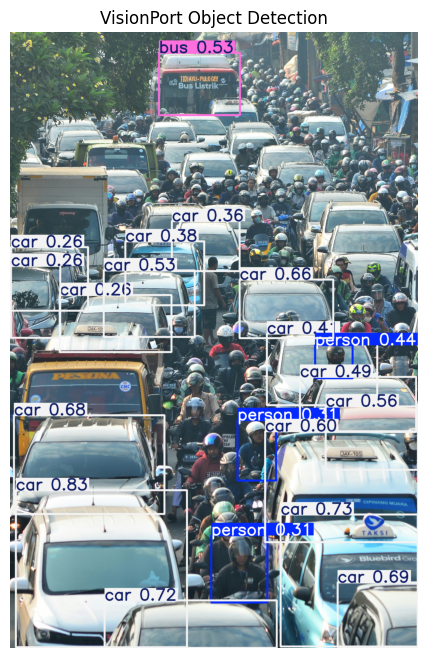

In [ ]:
annotated = result.plot()

plt.figure(figsize=(14, 8))
plt.imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.title("VisionPort Object Detection")
plt.show()

In [ ]:
vehicles = ["car", "truck", "bus", "motorcycle"]

animals = [
    "dog", "cat", "bird", "horse", "sheep",
    "cow", "elephant", "bear", "zebra", "giraffe"
]

detections = []

for box in result.boxes:

    class_id = int(box.cls[0])
    name = model.names[class_id]

    if name in vehicles:
        category = "Vehicle"
    elif name in animals:
        category = "Animal"
    else:
        category = "Other"

    detections.append({
        "Object": name,
        "Category": category,
        "Confidence": round(float(box.conf[0]) * 100, 2),
        "Bounding Box": [
            round(float(x), 2)
            for x in box.xyxy[0].tolist()
        ]
    })

df = pd.DataFrame(detections)

print("Total objects:", len(df))

if len(df):
    display(df)
else:
    print("No objects detected.")

Total objects: 20


,Object,Category,Confidence,Bounding Box
0,car,Vehicle,83.47,"[33.71, 2603.96, 1005.4, 3495.73]"
1,car,Vehicle,73.13,"[1537.74, 2741.77, 2316.9, 3491.35]"
2,car,Vehicle,71.70,"[537.41, 3229.49, 1515.9, 3499.08]"
3,car,Vehicle,69.19,"[1861.32, 3127.48, 2316.86, 3497.93]"
4,car,Vehicle,67.68,"[22.7, 2177.5, 877.4, 2738.02]"
5,car,Vehicle,66.23,"[1304.35, 1406.77, 1836.84, 1739.71]"
6,car,Vehicle,59.69,"[1449.59, 2268.38, 2318.0, 2898.82]"
7,car,Vehicle,55.62,"[1793.22, 2127.41, 2317.87, 2487.15]"
8,car,Vehicle,53.27,"[532.55, 1354.96, 1049.66, 1732.8]"
9,bus,Vehicle,52.75,"[846.99, 118.14, 1306.97, 472.7]"


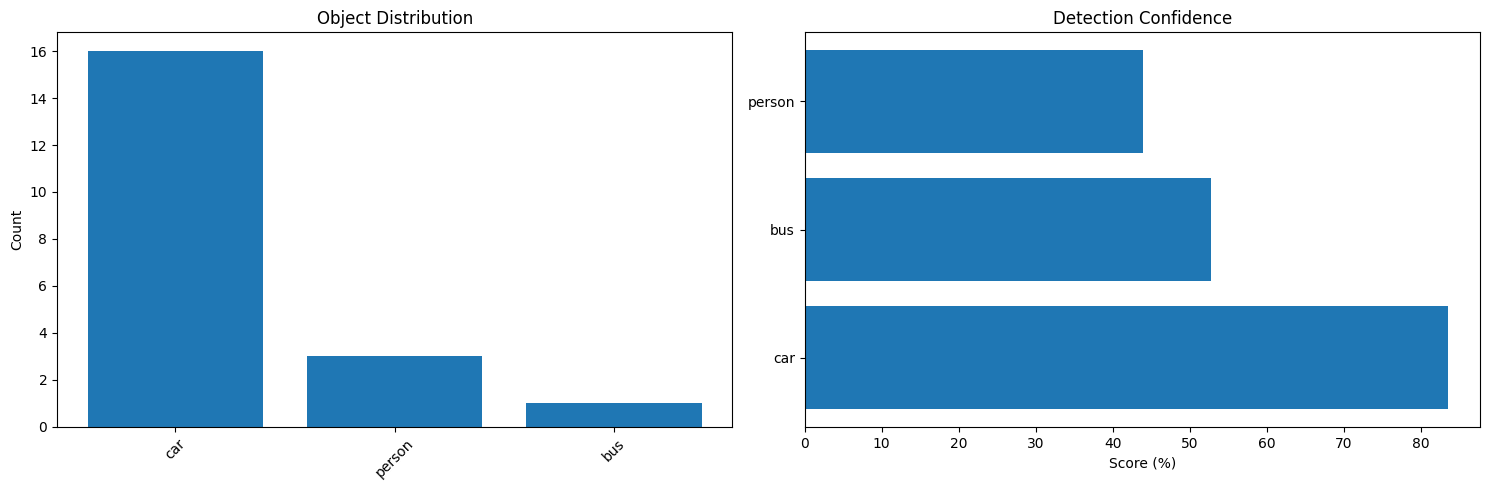

Category distribution:


,Count
Category,
Vehicle,17
Other,3


In [ ]:
if len(df):

    fig, axes = plt.subplots(1, 2, figsize=(15, 5))

    counts = df["Object"].value_counts()

    axes[0].bar(counts.index, counts.values)
    axes[0].set_title("Object Distribution")
    axes[0].set_ylabel("Count")
    axes[0].tick_params(axis="x", rotation=45)

    axes[1].barh(
        df["Object"],
        df["Confidence"]
    )

    axes[1].set_title("Detection Confidence")
    axes[1].set_xlabel("Score (%)")

    plt.tight_layout()
    plt.show()

    print("Category distribution:")
    display(df["Category"].value_counts().to_frame("Count"))

In [ ]:
print("Exporting model to ONNX...")

ONNX_PATH = model.export(
    format="onnx",
    imgsz=640,
    opset=17,
    simplify=False
)

onnx_model = onnx.load(ONNX_PATH)

onnx.checker.check_model(onnx_model)

print("ONNX export successful!")
print("ONNX file:", ONNX_PATH)

Exporting model to ONNX...
Ultralytics 8.4.210 🚀 Python-3.13.16 torch-2.14.1+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
YOLO11n summary (fused): 100 layers, 2,616,248 parameters, 0 gradients, 6.5 GFLOPs

PyTorch: starting from 'yolo11n.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 84, 8400) (5.4 MB)

ONNX: starting export with onnx 1.23.2 opset 17...
ONNX: export success ✅ 0.8s, saved as 'yolo11n.onnx' (10.2 MB)

Export complete (1.2s)
Results saved to /content/yolo11n.onnx
Predict:         yolo predict task=detect model=yolo11n.onnx imgsz=640 
Validate:        yolo val task=detect model=yolo11n.onnx imgsz=640  
Visualize:       https://netron.app
ONNX export successful!
ONNX file: yolo11n.onnx


In [ ]:
print("Checking TensorRT availability...")

try:
    import tensorrt as trt

    print("TensorRT version:", trt.__version__)

    if GPU_AVAILABLE:
        try:
            ENGINE_PATH = model.export(
                format="engine",
                imgsz=640,
                half=True,
                device=0
            )

            print("TensorRT engine created:", ENGINE_PATH)

        except Exception as e:
            ENGINE_PATH = None
            print("TensorRT engine export failed:", str(e))

    else:
        ENGINE_PATH = None
        print("No NVIDIA GPU available for engine execution.")

except ImportError:
    ENGINE_PATH = None
    print("TensorRT unavailable in this runtime.")
    print("ONNX model remains available.")

Checking TensorRT availability...
TensorRT unavailable in this runtime.
ONNX model remains available.


In [ ]:
REPOSITORY = "/content/model_repository"
MODEL_NAME = "visionport_detector"

MODEL_VERSION = os.path.join(
    REPOSITORY,
    MODEL_NAME,
    "1"
)

os.makedirs(MODEL_VERSION, exist_ok=True)

shutil.copy(
    ONNX_PATH,
    os.path.join(MODEL_VERSION, "model.onnx")
)

onnx_input = onnx_model.graph.input[0]
onnx_output = onnx_model.graph.output[0]

def get_shape(tensor):
    return [
        d.dim_value if d.HasField("dim_value") else -1
        for d in tensor.type.tensor_type.shape.dim
    ]

input_shape = get_shape(onnx_input)
output_shape = get_shape(onnx_output)

def format_dims(shape):
    return ", ".join(map(str, shape))

config = f'''
name: "{MODEL_NAME}"
platform: "onnxruntime_onnx"
max_batch_size: 0

input [
 {{
  name: "{onnx_input.name}"
  data_type: TYPE_FP32
  dims: [ {format_dims(input_shape)} ]
 }}
]

output [
 {{
  name: "{onnx_output.name}"
  data_type: TYPE_FP32
  dims: [ {format_dims(output_shape)} ]
 }}
]
'''

with open(
    os.path.join(REPOSITORY, MODEL_NAME, "config.pbtxt"),
    "w"
) as f:
    f.write(config)

print("Triton repository prepared!")
print("Model:", MODEL_NAME)
print("Input:", input_shape)
print("Output:", output_shape)

Triton repository prepared!
Model: visionport_detector
Input: [1, 3, 640, 640]
Output: [1, 84, 8400]


In [ ]:
app = FastAPI(title="VisionPort AI System")

@app.get("/")
def home():
    return {
        "project": "VisionPort",
        "status": "Running",
        "model": "YOLO11n"
    }


@app.get("/health")
def health():
    return {
        "api": "healthy",
        "gpu": GPU_AVAILABLE
    }


@app.post("/predict")
async def predict(file: UploadFile = File(...)):

    if file.content_type not in [
        "image/jpeg",
        "image/png",
        "image/webp"
    ]:
        raise HTTPException(
            status_code=400,
            detail="Unsupported image format"
        )

    try:
        contents = await file.read()

        img = Image.open(
            BytesIO(contents)
        ).convert("RGB")

    except Exception:
        raise HTTPException(
            status_code=400,
            detail="Invalid image"
        )

    prediction = model.predict(
        source=img,
        conf=0.25,
        device=0 if GPU_AVAILABLE else "cpu",
        verbose=False
    )[0]

    output = []

    for box in prediction.boxes:

        class_id = int(box.cls[0])

        output.append({
            "object": model.names[class_id],
            "confidence": round(float(box.conf[0]), 4),
            "bbox": [
                round(float(v), 2)
                for v in box.xyxy[0].tolist()
            ]
        })

    return {
        "filename": file.filename,
        "total_objects": len(output),
        "detections": output
    }


print("FastAPI application created!")

FastAPI application created!


In [ ]:
import nest_asyncio
import uvicorn

nest_asyncio.apply()

def start_server():
    uvicorn.run(
        app,
        host="127.0.0.1",
        port=8000,
        log_level="error"
    )

server_thread = threading.Thread(
    target=start_server,
    daemon=True
)

server_thread.start()

time.sleep(3)

print("FastAPI server started!")

FastAPI server started!


In [ ]:
with open(IMAGE_PATH, "rb") as image_file:

    response = requests.post(
        "http://127.0.0.1:8000/predict",
        files={
            "file": (
                os.path.basename(IMAGE_PATH),
                image_file,
                "image/jpeg"
            )
        }
    )

print("HTTP Status:", response.status_code)

api_result = response.json()

display(
    pd.DataFrame(api_result["detections"])
)

print("Total detected objects:", api_result["total_objects"])

HTTP Status: 200


,object,confidence,bbox
0,car,0.8347,"[33.71, 2603.96, 1005.4, 3495.73]"
1,car,0.7313,"[1537.74, 2741.77, 2316.9, 3491.35]"
2,car,0.7170,"[537.41, 3229.49, 1515.9, 3499.08]"
3,car,0.6919,"[1861.32, 3127.48, 2316.86, 3497.93]"
4,car,0.6768,"[22.7, 2177.5, 877.4, 2738.02]"
5,car,0.6623,"[1304.35, 1406.77, 1836.84, 1739.71]"
6,car,0.5969,"[1449.59, 2268.38, 2318.0, 2898.82]"
7,car,0.5562,"[1793.22, 2127.41, 2317.87, 2487.15]"
8,car,0.5327,"[532.55, 1354.96, 1049.66, 1732.8]"
9,bus,0.5275,"[846.99, 118.14, 1306.97, 472.7]"


Total detected objects: 20


In [ ]:
TRITON_URL = "localhost:8001"

try:
    import tritonclient.grpc as grpcclient

    triton = grpcclient.InferenceServerClient(
        url=TRITON_URL
    )

    print("Triton live:", triton.is_server_live())
    print("Triton ready:", triton.is_server_ready())

except Exception as e:
    print("Triton server is not connected.")
    print("Reason:", str(e))
    print("Repository is prepared for deployment.")

Triton server is not connected.
Reason: [StatusCode.UNAVAILABLE] failed to connect to all addresses; last error: UNKNOWN: ipv4:127.0.0.1:8001: Failed to connect to remote host: Connection refused
Repository is prepared for deployment.


In [ ]:
print("\n" + "=" * 55)
print("       VISIONPORT - SYSTEM STATUS REPORT")
print("=" * 55)

status = {
    "YOLO11 Model": "Loaded",
    "GPU": "Available" if GPU_AVAILABLE else "CPU Mode",
    "Object Detection": "Completed",
    "ONNX Export": "Completed",
    "TensorRT Engine": "Created" if ENGINE_PATH else "Not Available",
    "Triton Repository": "Prepared",
    "FastAPI": "Running",
    "Triton Server": "External connection required"
}

for component, state in status.items():
    print(f"{component:<25}: {state}")

print("=" * 55)
print("VISIONPORT EXECUTION FINISHED")


       VISIONPORT - SYSTEM STATUS REPORT
YOLO11 Model             : Loaded
GPU                      : Available
Object Detection         : Completed
ONNX Export              : Completed
TensorRT Engine          : Not Available
Triton Repository        : Prepared
FastAPI                  : Running
Triton Server            : External connection required
VISIONPORT EXECUTION FINISHED


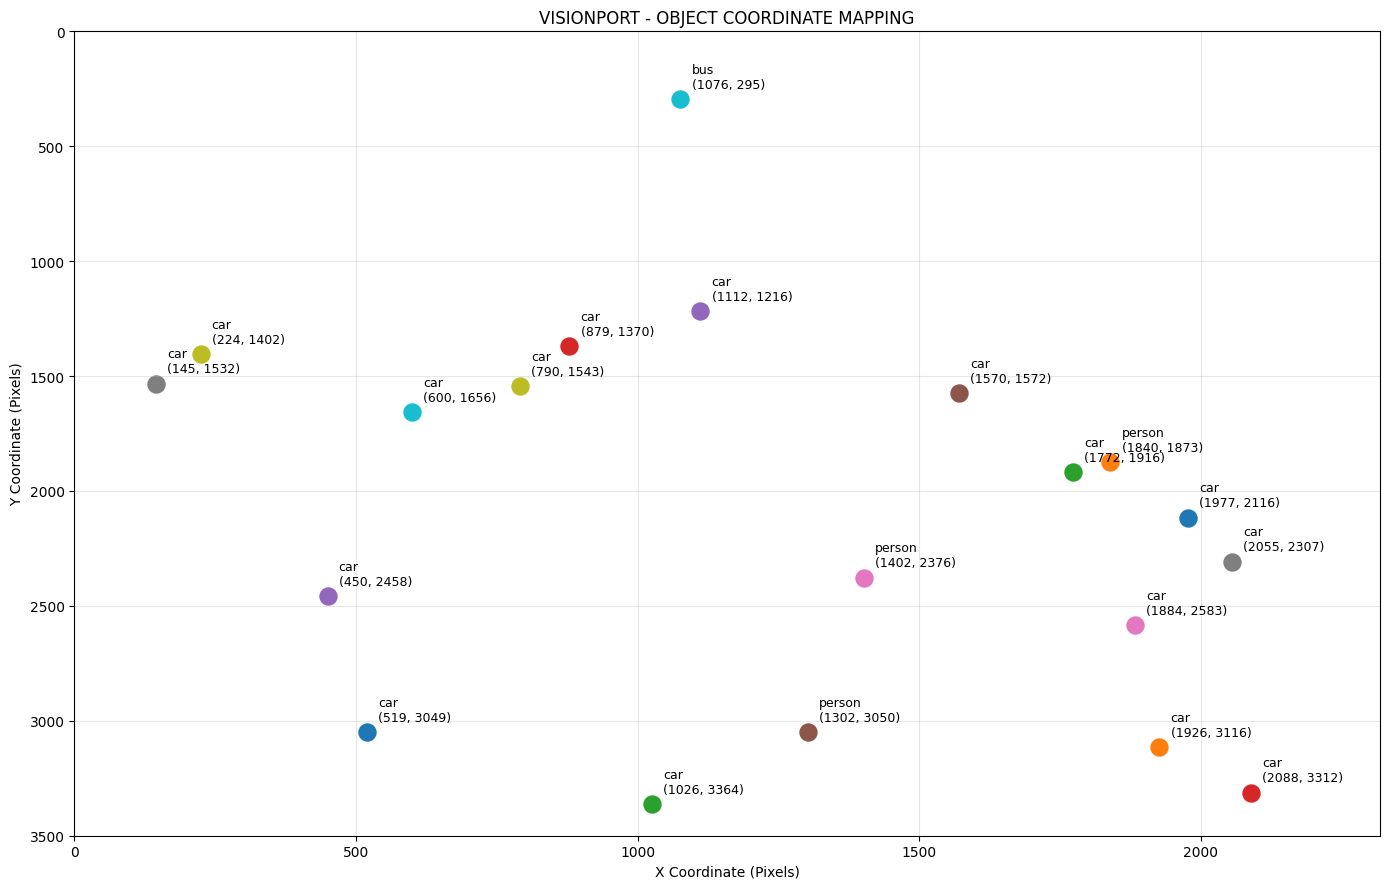

Detected Object Coordinates:


,Object,Center X,Center Y,X1,Y1,X2,Y2
0,car,519.0,3049.0,33,2603,1005,3495
1,car,1926.5,3116.0,1537,2741,2316,3491
2,car,1026.0,3364.0,537,3229,1515,3499
3,car,2088.5,3312.0,1861,3127,2316,3497
4,car,449.5,2457.5,22,2177,877,2738
5,car,1570.0,1572.5,1304,1406,1836,1739
6,car,1883.5,2583.0,1449,2268,2318,2898
7,car,2055.0,2307.0,1793,2127,2317,2487
8,car,790.5,1543.0,532,1354,1049,1732
9,bus,1076.0,295.0,846,118,1306,472


In [ ]:

import matplotlib.pyplot as plt
import pandas as pd

# Get image dimensions
image_width, image_height = image.size

# Extract coordinates directly from YOLO results
coordinate_data = []

for box in result.boxes:

    class_id = int(box.cls[0])
    name = model.names[class_id]

    x1, y1, x2, y2 = map(
        int, box.xyxy[0].tolist()
    )

    center_x = (x1 + x2) / 2
    center_y = (y1 + y2) / 2

    coordinate_data.append({
        "Object": name,
        "Center X": center_x,
        "Center Y": center_y,
        "X1": x1,
        "Y1": y1,
        "X2": x2,
        "Y2": y2
    })

# Create DataFrame
coordinate_df = pd.DataFrame(coordinate_data)

if coordinate_df.empty:
    print("No objects detected. Try another image.")

else:
    # Plot coordinate graph
    plt.figure(figsize=(14, 9))

    for _, row in coordinate_df.iterrows():

        x = row["Center X"]
        y = row["Center Y"]

        plt.scatter(x, y, s=150)

        plt.annotate(
            f"{row['Object']}\n({x:.0f}, {y:.0f})",
            (x, y),
            xytext=(8, 8),
            textcoords="offset points",
            fontsize=9
        )

    plt.xlim(0, image_width)
    plt.ylim(image_height, 0)

    plt.xlabel("X Coordinate (Pixels)")
    plt.ylabel("Y Coordinate (Pixels)")

    plt.title("VISIONPORT - OBJECT COORDINATE MAPPING")

    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    print("Detected Object Coordinates:")
    display(coordinate_df)
